In [1]:
import simulation
import HminLower
import shannonLower
import matplotlib.pyplot as plt
import numpy as np
import ShannonGEAT
np.random.seed(42) ## To get same figure as paper, run everything in order.

# Photon number

## Ideal

In [2]:
res = {'shannon': [], 'hmin': [], 'deltas': [], 'shannon2': [], 'hmin2': []}
alphas = np.linspace(0.07, 2.5, 30)

for alpha in alphas:
    delta, p = simulation.getProbas(alpha, 1, 0, '0')
    hmin = HminLower.getHmin(p, delta, 7/8)
    shannon = shannonLower.runOpti(delta, p, 7/8)
    hmin2 = HminLower.getHmin(p, delta, 1/2)
    shannon2 = shannonLower.runOpti(delta, p, 1/2)
    res['shannon'].append(shannon)
    res['hmin'].append(hmin)
    res['shannon2'].append(shannon2)
    res['hmin2'].append(hmin2)
    res['deltas'].append(delta)

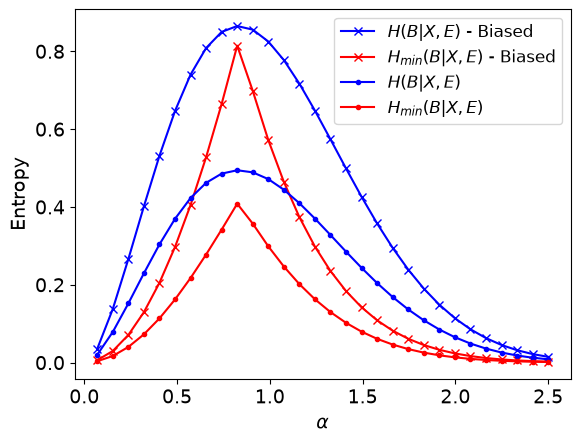

In [3]:
plt.figure()
plt.plot(alphas, res['shannon'], 'b-x', label=r'$H(B|X,E)$ - Biased')
plt.plot(alphas, res['hmin'], 'r-x', label=r'$H_{min}(B|X,E)$ - Biased')
plt.plot(alphas, res['shannon2'], 'b.-', label=r'$H(B|X,E)$')
plt.plot(alphas, res['hmin2'], 'r.-', label=r'$H_{min}(B|X,E)$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)
plt.savefig(
    "images/PerfNumber.pdf",
    bbox_inches="tight"
)

## Bad detector

In [4]:
res = {'shannon': [], 'hmin': [], 'deltas': [], 'shannon2': [], 'hmin2': []}
alphas = np.linspace(0.07, 2.5, 30)

for alpha in alphas:
    delta, p = simulation.getProbas(alpha, 0.7, 1e-6, '0', True)
    hmin = HminLower.getHmin(p, delta, 7/8)
    shannon = shannonLower.runOpti(delta, p, 7/8)
    hmin2 = HminLower.getHmin(p, delta, 1/2)
    shannon2 = shannonLower.runOpti(delta, p, 1/2)
    res['shannon'].append(shannon)
    res['hmin'].append(hmin)
    res['shannon2'].append(shannon2)
    res['hmin2'].append(hmin2)
    res['deltas'].append(delta)

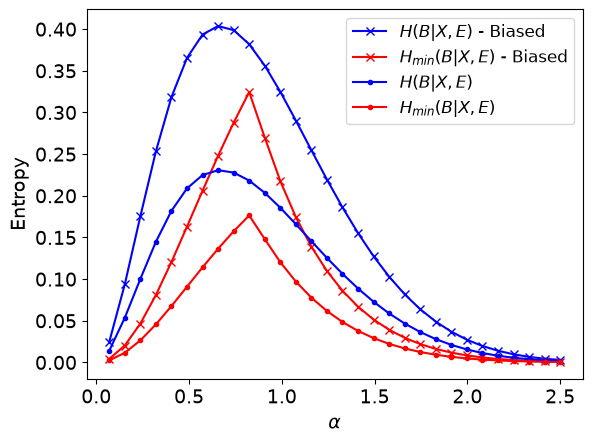

In [5]:
plt.figure()
plt.plot(alphas, res['shannon'], 'b-x', label=r'$H(B|X,E)$ - Biased')
plt.plot(alphas, res['hmin'], 'r-x', label=r'$H_{min}(B|X,E)$ - Biased')
plt.plot(alphas, res['shannon2'], 'b.-', label=r'$H(B|X,E)$')
plt.plot(alphas, res['hmin2'], 'r.-', label=r'$H_{min}(B|X,E)$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)
plt.savefig(
    "images/DetectorNumber.pdf",
    bbox_inches="tight"
)

## Main Text Figure

In [5]:
res = {'shannon': [], 'hmin': [], 'deltas': [], 'geat': []}
alphas = np.linspace(0.07, 2.5, 30)

for alpha in alphas:
    delta, p = simulation.getProbas(alpha, 0.25, 1e-6, '0', True)
    hmin = HminLower.getHmin(p, delta, 7/8)
    shannon = shannonLower.runOpti(delta, p, 7/8)
    res['shannon'].append(shannon)
    res['hmin'].append(hmin)
    res['deltas'].append(delta)
    ps = [p]
    for i in range(4):
        _, p = simulation.doSimul(alpha, 7/8, '0', 10**7, 0.25, True)
        ps.append(p[0])
    val = ShannonGEAT.Hgeat(ps, delta, 10**7, 0.95, "bff", 7/8)
    res['geat'].append(val)

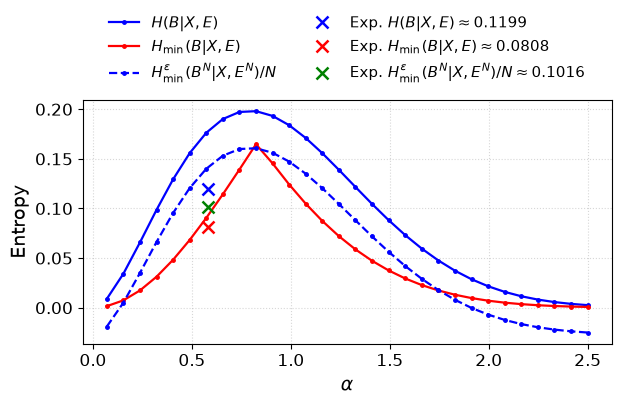

In [11]:
fig, ax = plt.subplots(figsize=(6.2, 4.0))

# Main curves
ax.plot(
    alphas, res['shannon'],
    'b.-', lw=1.6, ms=5,
    label=r'$H(B|X,E)$'
)
ax.plot(
    alphas, res['hmin'],
    'r.-', lw=1.6, ms=5,
    label=r'$H_{\min}(B|X,E)$'
)
ax.plot(
    alphas, res['geat'],
    'b.--', lw=1.6, ms=5,
    label=r'$H_{\min}^{\varepsilon}(B^N|X,E^N)/N$'
)

# Experimental points at alpha = 0.58
alpha_exp = 0.58

ax.plot(
    alpha_exp, 0.11994653753140838,
    marker='x', ms=8, mfc='none', mec='blue', mew=1.8,
    linestyle='none',
    label=r'Exp. $H(B|X,E)\approx0.1199$'
)

ax.plot(
    alpha_exp, 0.08087655931761581,
    marker='x', ms=8, mfc='none', mec='red', mew=1.8,
    linestyle='none',
    label=r'Exp. $H_{\min}(B|X,E)\approx0.0808$'
)

ax.plot(
    alpha_exp, 0.10166482557961125,
    marker='x', ms=8, mfc='none', mec='green', mew=1.8,
    linestyle='none',
    label=r'Exp. $H_{\min}^{\varepsilon}(B^N|X,E^N)/N\approx0.1016$'
)

ax.set_xlabel(r'$\alpha$', fontsize=14)
ax.set_ylabel('Entropy', fontsize=14)

ax.tick_params(axis='both', labelsize=12)
ax.grid(ls=':', alpha=0.5)

ax.legend(
    loc='lower center',
    bbox_to_anchor=(0.5, 1.01),
    ncol=2,
    fontsize=11,
    frameon=False
)

fig.tight_layout(pad=0.5)
fig.savefig(
    "images/PhotonNumberRes.pdf",
    bbox_inches="tight"
)
## green one different: blue dotted / red for BPSK, change name: finite statistics
plt.show()

## Bad detector and source

In [15]:
res = {'shannon': [], 'hmin': [], 'deltas': [], 'shannon2': [], 'hmin2': []}
alphas = np.linspace(0.07, 2.5, 30)

for alpha in alphas:
    amax, delta, p = simulation.doSimul(alpha, 7/8, '0', 100000, 0.7, True, True)
    hmin = HminLower.getHmin(p[0], delta, 7/8)
    shannon = shannonLower.runOpti(delta, p[0], 7/8)
    amax, delta, p = simulation.doSimul(alpha, 1/2, '0', 100000, 0.7, True, True)
    hmin2 = HminLower.getHmin(p[0], delta, 1/2)
    shannon2 = shannonLower.runOpti(delta, p[0], 1/2)
    res['shannon'].append(shannon)
    res['hmin'].append(hmin)
    res['shannon2'].append(shannon2)
    res['hmin2'].append(hmin2)
    res['deltas'].append(delta)

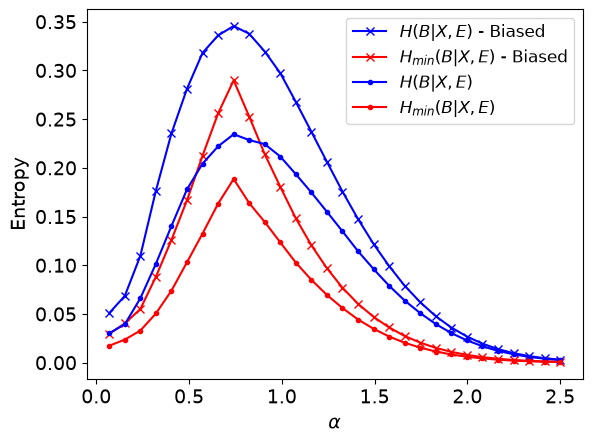

In [16]:
plt.figure()
plt.plot(alphas, res['shannon'], 'b-x', label=r'$H(B|X,E)$ - Biased')
plt.plot(alphas, res['hmin'], 'r-x', label=r'$H_{min}(B|X,E)$ - Biased')
plt.plot(alphas, res['shannon2'], 'b.-', label=r'$H(B|X,E)$')
plt.plot(alphas, res['hmin2'], 'r.-', label=r'$H_{min}(B|X,E)$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)
plt.savefig(
    "images/BadSourceNumber.pdf",
    bbox_inches="tight"
)

## Blocksize study

In [66]:
alpha = 0.58
npoints = np.linspace(3, 7, 10)
_, delta, pref = simulation.doSimul(alpha, 7/8, '0', 100000, 0.7, True, True)
H_theo = shannonLower.runOpti(delta, p[0], 7/8)

In [67]:
vals = []
for npoint in npoints:
    ps = [pref[0]]
    for i in range(5):
        _, _, p = simulation.doSimul(alpha, 7/8, '0', int(10**(npoint)), 0.7, True, True)
        ps.append(p[0])
    val3 = ShannonGEAT.Hgeat(ps, delta, int(10**npoint), 0.95, "bff", 7/8)
    vals.append(val3)
    

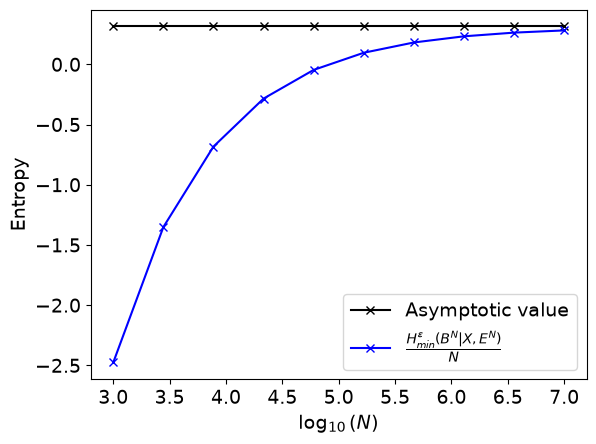

In [68]:
plt.figure()
Hts = [H_theo]*10
plt.plot(npoints, Hts, 'kx-', label=r'Asymptotic value')
plt.plot(npoints, vals, 'bx-', label=r'$\frac{H_{min}^\epsilon(B^N|X,E^N)}{N}$')
plt.xlabel(r"$\log_{10}(N)$", fontsize=14)
plt.ylabel(r"Entropy", fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.savefig(
    "images/BlockSizeNumber.pdf",
    bbox_inches="tight"
)

## Bad detector, source + finite size

In [54]:
res = {'alpha': [], 'vals': [], 'vals2': []}
alphas = np.linspace(0.07, 2.5, 30)

for alpha in alphas:
    _, delta, p = simulation.doSimul(alpha, 7/8, '0', 100000, 0.7, True, True)
    _, delta2, p2 = simulation.doSimul(alpha, 1/2, '0', 100000, 0.7, True, True)
    ps = [p[0]]
    ps2 = [p2[0]]
    for i in range(5):
        _, _, p = simulation.doSimul(alpha, 7/8, '0', 100000, 0.7, True, True)
        _, _, p2 = simulation.doSimul(alpha, 1/2, '0', 100000, 0.7, True, True)
        ps.append(p[0])
        ps2.append(p2[0])
    val = ShannonGEAT.Hgeat(ps, delta, 100000, 0.95, "bff", 7/8)
    val2 = ShannonGEAT.Hgeat(ps, delta2, 100000, 0.95, "bff", 1/2)
    res['vals'].append(val)
    res['vals2'].append(val2)
    res['alpha'].append(alpha)

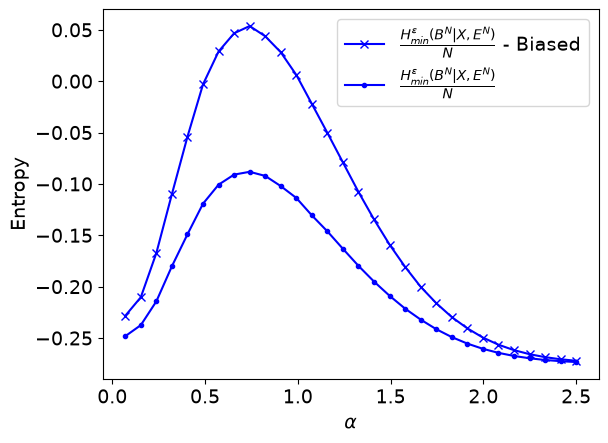

In [55]:
plt.figure()
plt.plot(alphas, res['vals'], 'bx-', label=r'$\frac{H_{min}^\epsilon(B^N|X,E^N)}{N}$ - Biased')
plt.plot(alphas, res['vals2'], 'b.-', label=r'$\frac{H_{min}^\epsilon(B^N|X,E^N)}{N}$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.savefig(
    "images/FiniteSizeNumber.pdf",
    bbox_inches="tight"
)

## Real data

In [7]:
alpha = 0.58
delta, _ = simulation.getProbas(alpha, 0.25, 1e-6, '0', True)
p = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.0288181271, 1: 0.1254143637}, 2: {0: 0.9711818729, 1: 0.8745856363}} #comment for simulated value, this is exp data
shannonLower.runOpti(delta, p, 7/8) #Hbff

np.float64(0.11994646821352983)

In [8]:
HminLower.getHmin(p, delta, 7/8) #Hmin

np.float64(0.08087655945496022)

In [9]:
p1 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.0285433071, 1: 0.1254505528}, 2: {0: 0.9714566929, 1: 0.8745494472}}
p2 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.0280568533, 1: 0.1253347555}, 2: {0: 0.9719431467, 1: 0.8746652445}} 
p3 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.0296852703, 1: 0.1253951218}, 2: {0: 0.9703147297, 1: 0.8746048782}} 
p4 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.02892193, 1: 0.1253726933}, 2: {0: 0.97107807, 1: 0.8746273067}} 
ps = [p, p1, p2, p3, p4]
ShannonGEAT.Hgeat(ps, delta, 5*10**7, 0.95, "bff", 7/8, 0, True)


Using 4 blocks out of 4 (blocks [0, 1, 2, 3])


np.float64(0.10166482557961125)

# BPSK 

## Ideal

In [19]:
res = {'shannon': [], 'hmin': [], 'deltas': []}
alphas = np.linspace(0, 2, 30)

for alpha in alphas:
    delta, p = simulation.getProbas(alpha, 1, 0, '2', False)
    hmin = HminLower.getHmin(p, delta, 1/2)
    shannon = shannonLower.runOpti(delta, p, 1/2)
    res['shannon'].append(shannon)
    res['hmin'].append(hmin)
    res['deltas'].append(delta)

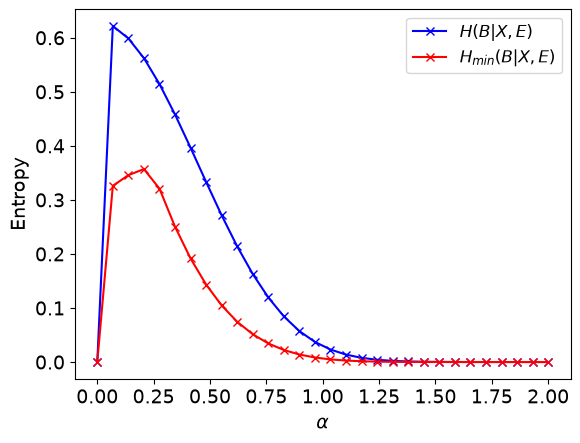

In [20]:
plt.figure()
plt.plot(alphas, res['shannon'], 'bx-', label=r'$H(B|X,E)$')
plt.plot(alphas, res['hmin'], 'rx-', label=r'$H_{min}(B|X,E)$')
plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel(r'Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=12)
plt.savefig(
    "images/PerfBPSK.pdf",
    bbox_inches="tight"
)

## $p_{noise}$ model

In [21]:
res = [{'deltas': [], 'shannon': [], 'hmin': []} for _ in range(4)]
alphas = np.linspace(0.01, 1.3, 20)
pnoises = np.linspace(0, 1, 4)

for i, pnoise in enumerate(pnoises):
    for alpha in alphas:
        delta, p = simulation.doSimul(alpha, 1/2, '2', 1000000, 1, False, False, 0, pnoise)
        hmin = HminLower.getHmin(p[0], delta, 1/2)
        shannon = shannonLower.runOpti(delta, p[0], 1/2)
        res[i]['shannon'].append(shannon)
        res[i]['hmin'].append(hmin)
        res[i]['deltas'].append(delta)

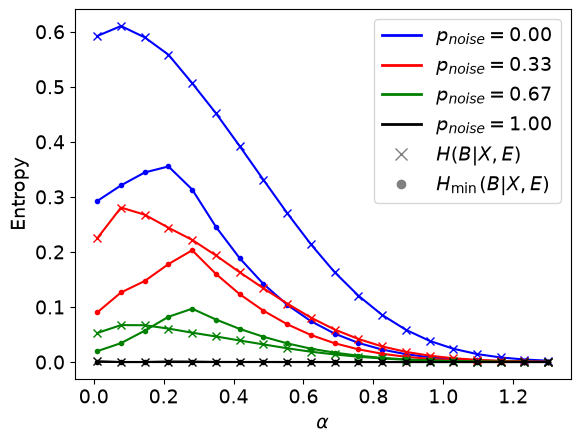

In [22]:
from matplotlib.lines import Line2D

plt.figure()

colors = ['b', 'r', 'g', 'k']

for i in range(4):
    plt.plot(alphas, res[i]['shannon'], colors[i] + 'x-')
    plt.plot(alphas, res[i]['hmin'], colors[i] + '.-')

plt.xlabel(r'$\alpha$', fontsize=14)
plt.ylabel('Entropy', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

# Legend for colors: p_noise
color_handles = [
    Line2D([0], [0], color=colors[i], lw=2,
           label=rf'$p_{{noise}} = {pnoises[i]:.2f}$')
    for i in range(4)
]

# Legend for markers: entropy type
marker_handles = [
    Line2D([0], [0], color='gray', marker='x', linestyle='None',
           markersize=8, label=r'$H(B|X,E)$'),
    Line2D([0], [0], color='gray', marker='.', linestyle='None',
           markersize=12, label=r'$H_{\min}(B|X,E)$')
]

plt.legend(handles=color_handles + marker_handles, fontsize=14)

plt.savefig("images/BadSourceBPSK.pdf", bbox_inches="tight")

## Main Text Figure

In [13]:
res = [{'shannon': [], 'hmin': [], 'deltas': [], 'geat': [], 'geat2': []} for _ in range(1)]
alphas = np.linspace(0, 1.4, 30)
pnoises = [0.6]

for i, pnoise in enumerate(pnoises):
    for alpha in alphas:
        delta, p = simulation.getProbas(alpha, 1, 0, '2', False)
        p[1][0] = (1-pnoise)*p[1][0] + pnoise*1/2
        p[1][1] = (1-pnoise)*p[1][1] + pnoise*1/2
        p[2][0] = (1-pnoise)*p[2][0] + pnoise*1/2
        p[2][1] = (1-pnoise)*p[2][1] + pnoise*1/2
        hmin = HminLower.getHmin(p, delta, 1/2)
        shannon = shannonLower.runOpti(delta, p, 1/2)
        res[i]['shannon'].append(shannon)
        res[i]['hmin'].append(hmin)
        res[i]['deltas'].append(delta)
        ps=[p]
        for _ in range(4):
            _, p = simulation.doSimul(alpha, 1/2, '2', 10**7, 1, False, False, 0, 0.6)
            ps.append(p[0])
        val = ShannonGEAT.Hgeat(ps, delta, 10**7, 0.95, "hmin", 1/2)
        res[i]['geat'].append(val)


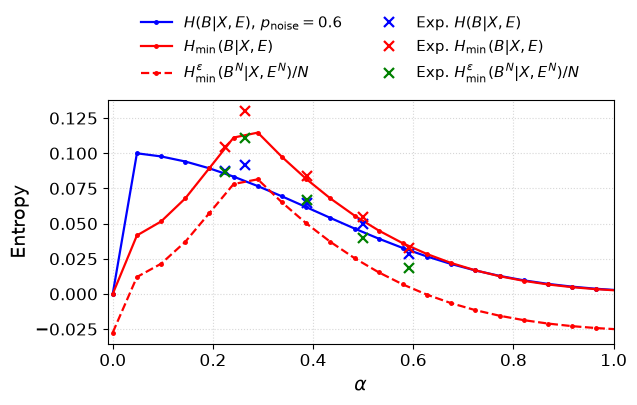

In [52]:
fig, ax = plt.subplots(figsize=(6.2, 4.0))

# Theoretical curves
ax.plot(
    alphas, res[0]['shannon'],
    'b.-', lw=1.6, ms=5,
    label=rf'$H(B|X,E)$, $p_{{\mathrm{{noise}}}}={pnoises[0]:.1f}$'
)

ax.plot(
    alphas, res[0]['hmin'],
    'r.-', lw=1.6, ms=5,
    label=r'$H_{\min}(B|X,E)$'
)

ax.plot(
    alphas, res[0]['geat'],
    'r.--', lw=1.6, ms=5,
    label=r'$H_{\min}^{\varepsilon}(B^N|X,E^N)/N$'
)

# Experimental data
alpha_exp = np.sqrt([0.05, 0.07, 0.15, 0.25, 0.35])

H_exp = [
    0.0877,
    0.0915,
    0.0649,
    0.0497,
    0.0286
]

Hmin_exp = [
    0.1045,
    0.1299,
    0.0837,
    0.0550,
    0.0325
]

GEAT_exp = [
    0.0869,
    0.1110,
    0.0670,
    0.0396,
    0.0181
]

# Experimental points
ax.plot(
    alpha_exp, H_exp,
    'x', ms=7, mfc='none', mec='blue', mew=1.6,
    linestyle='none', zorder=5,
    label=r'Exp. $H(B|X,E)$'
)

ax.plot(
    alpha_exp, Hmin_exp,
    'x', ms=7, mfc='none', mec='red', mew=1.6,
    linestyle='none', zorder=5,
    label=r'Exp. $H_{\min}(B|X,E)$'
)

ax.plot(
    alpha_exp, GEAT_exp,
    'x', ms=7, mfc='none', mec='green', mew=1.6,
    linestyle='none', zorder=5,
    label=r'Exp. $H_{\min}^{\varepsilon}(B^N|X,E^N)/N$'
)

# Axes
ax.set_xlabel(r'$\alpha$', fontsize=11)
ax.set_ylabel('Entropy', fontsize=11)

ax.tick_params(axis='both', labelsize=9)
ax.grid(ls=':', alpha=0.5)

# Compact legend above plot
ax.legend(
    loc='lower center',
    bbox_to_anchor=(0.5, 1.01),
    ncol=2,
    fontsize=8,
    frameon=False,
    columnspacing=1.1,
    handlelength=2.2,
    handletextpad=0.5
)
ax.set_xlabel(r'$\alpha$', fontsize=14)
ax.set_ylabel('Entropy', fontsize=14)

ax.tick_params(axis='both', labelsize=12)

ax.legend(
    loc='lower center',
    bbox_to_anchor=(0.5, 1.01),
    ncol=2,
    fontsize=11,
    frameon=False
)

ax.set_xlim(right=1, left=-0.01)
fig.tight_layout(pad=0.5)

fig.savefig(
    "images/BPSKRes.pdf",
    bbox_inches="tight"
)

## Blocksize Study

In [ ]:
alpha = 0.07 ## this is max entropy value with noise (i.e closer to 0)
npoints = np.linspace(3, 7, 10)
delta, pref = simulation.doSimul(alpha, 1/2, '2', 10000000, 1, False, False, 0, 0.6)
H_theo = shannonLower.runOpti(delta, pref[0], 1/2)

In [75]:
vals = []
for npoint in npoints:
    ps = [pref[0]]
    for i in range(5):
        _, p = simulation.doSimul(alpha, 1/2, '2', int(10**(npoint)), 1, False, False, 0, 0.6)
        ps.append(p[0])
    val = ShannonGEAT.Hgeat(ps, delta, int(10**(npoint)), 0.95, "hmin", 1/2)
    vals.append(val)

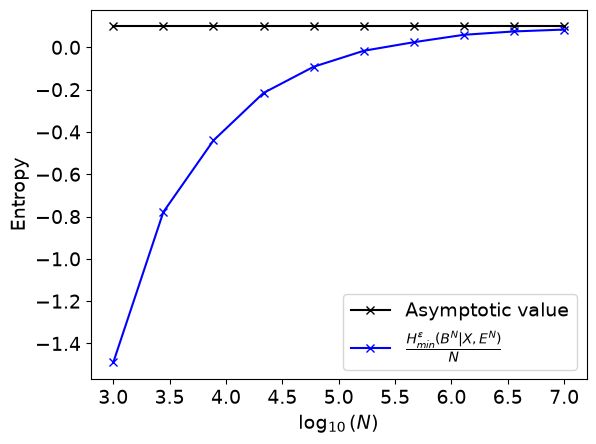

In [ ]:
plt.figure()
Hts = [H_theo]*10
plt.plot(npoints, Hts, 'kx-', label=r'Asymptotic value')
plt.plot(npoints, vals, 'bx-', label=r'$\frac{H_{min}^\epsilon(B^N|X,E^N)}{N}$')
plt.xlabel(r"$\log_{10}(N)$", fontsize=14)
plt.ylabel(r"Entropy", fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.savefig(
    "images/BlockSizeBPSK.pdf",
    bbox_inches="tight"
)

## Real data

### $\mu=0.05$

In [ ]:
## Computing Hbff
alpha = np.sqrt(0.05)
delta, _ = simulation.getProbas(alpha, 1, 0, '2')
p = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.5701209883628657, 1: 0.4303265540440196}, 2: {0: 0.4298790116371343, 1: 0.5696734459559804}} #comment for simulated value, this is exp data
shannonLower.runOpti(delta, p, 1/2)

np.float64(0.0877580370836375)

In [26]:
## Hmin
HminLower.getHmin(p, delta, 1/2)

np.float64(0.10453794200660793)

In [ ]:
## Comparing with model, using pnoise
pnoise=0.6
deltanoised, pnoised = simulation.getProbas(alpha, 1, 0, '2', False)
pnoised[1][0] = (1-pnoise)*pnoised[1][0] + pnoise*1/2
pnoised[1][1] = (1-pnoise)*pnoised[1][1] + pnoise*1/2
pnoised[2][0] = (1-pnoise)*pnoised[2][0] + pnoise*1/2
pnoised[2][1] = (1-pnoise)*pnoised[2][1] + pnoise*1/2
hmin = HminLower.getHmin(pnoised, deltanoised, 1/2)
shannon = shannonLower.runOpti(deltanoised, pnoised, 1/2)
shannon,hmin

(np.float64(0.08564646083796745), np.float64(0.10323344615423712))

In [28]:
## Computing GEAT value
p1 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.5708058377455325, 1: 0.42850202669006215}, 2: {0: 0.4291941622544675, 1: 0.5714979733099379}} 
p2 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.5677683791155907, 1: 0.4318336761107203}, 2: {0: 0.43223162088440925, 1: 0.5681663238892797}} 
p3 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.5685865570639924, 1: 0.4325027913530653}, 2: {0: 0.4314134429360076, 1: 0.5674972086469348}} 
p4 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.56675634849989, 1: 0.43343038377441184}, 2: {0: 0.43324365150011, 1: 0.5665696162255882}}
ps=[p,p1,p2,p3,p4]
ShannonGEAT.Hgeat(ps, delta, 5*10**7, 0.95, "hmin", 1/2, 8.57670*10**(-5), True)

Using 4 blocks out of 4 (blocks [0, 1, 2, 3])


np.float64(0.08694518086779843)

### $\mu=0.07$

In [32]:
## Computing asymptotic entropy + parameters for GEAT
alpha = np.sqrt(0.07)
delta, _ = simulation.getProbas(alpha, 0.25, 1e-6, '2')
p = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.5866236803022608, 1: 0.41436099695187384}, 2: {0: 0.4133763196977392, 1: 0.5856390030481261}} #comment for simulated value, this is exp data
shannonLower.runOpti(delta, p, 1/2)

np.float64(0.09157211138523902)

In [33]:
## Hmin
HminLower.getHmin(p, delta, 1/2)

np.float64(0.12994125917763652)

In [34]:
## Comparing with model, using pnoise
pnoise=0.6
deltanoised, pnoised = simulation.getProbas(alpha, 1, 0, '2', False)
pnoised[1][0] = (1-pnoise)*pnoised[1][0] + pnoise*1/2
pnoised[1][1] = (1-pnoise)*pnoised[1][1] + pnoise*1/2
pnoised[2][0] = (1-pnoise)*pnoised[2][0] + pnoise*1/2
pnoised[2][1] = (1-pnoise)*pnoised[2][1] + pnoise*1/2
hmin = HminLower.getHmin(pnoised, delta, 1/2)
shannon = shannonLower.runOpti(deltanoised, pnoised, 1/2)
shannon,hmin

(np.float64(0.08022235502802655), np.float64(0.12132919993543352))

In [35]:
## Computing GEAT value
p1 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.584423474622463, 1: 0.4160500303407748}, 2: {0: 0.415576525377537, 1: 0.5839499696592252}} 
p2 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.5857937339814735, 1: 0.41450023999141195}, 2: {0: 0.4142062660185265, 1: 0.585499760008588}} 
p3 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.5856540761153054, 1: 0.4136351044593741}, 2: {0: 0.41434592388469466, 1: 0.5863648955406259}} 
p4 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.5862191232056282, 1: 0.4136431523687366}, 2: {0: 0.41378087679437187, 1: 0.5863568476312634}}
ps=[p,p1,p2,p3,p4]
ShannonGEAT.Hgeat(ps, delta, 5*10**7, 0.95, "hmin", 1/2, 1.17040*10**(-4), True)

Using 4 blocks out of 4 (blocks [0, 1, 2, 3])


np.float64(0.11104862368787188)

### $\mu=0.15$

In [39]:
## Computing asymptotic entropy + parameters for GEAT
alpha = np.sqrt(0.15)
delta, _ = simulation.getProbas(alpha, 0.25, 1e-6, '2')
p = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.6150239165453663, 1: 0.3843549705230134}, 2: {0: 0.38497608345463374, 1: 0.6156450294769866}} #comment for simulated value, this is exp data
shannonLower.runOpti(delta, p, 1/2)

np.float64(0.06498139185067053)

In [40]:
## Hmin
HminLower.getHmin(p, delta, 1/2)

np.float64(0.08370595002187167)

In [41]:
## Comparing with model, using pnoise
pnoise=0.6
deltanoised, pnoised = simulation.getProbas(alpha, 1, 0, '2', False)
pnoised[1][0] = (1-pnoise)*pnoised[1][0] + pnoise*1/2
pnoised[1][1] = (1-pnoise)*pnoised[1][1] + pnoise*1/2
pnoised[2][0] = (1-pnoise)*pnoised[2][0] + pnoise*1/2
pnoised[2][1] = (1-pnoise)*pnoised[2][1] + pnoise*1/2
hmin = HminLower.getHmin(pnoised, deltanoised, 1/2)
shannon = shannonLower.runOpti(deltanoised, pnoised, 1/2)
shannon,hmin

(np.float64(0.061539185912402594), np.float64(0.08142862369809778))

In [43]:
## Computing GEAT value
p1 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.6132547049954431, 1: 0.3866555204508309}, 2: {0: 0.3867452950045569, 1: 0.6133444795491692}} 
p2 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.6085012476797629, 1: 0.39142822559055124}, 2: {0: 0.39149875232023706, 1: 0.6085717744094488}} 
p3 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.611660890241809, 1: 0.3886732770250026}, 2: {0: 0.3883391097581909, 1: 0.6113267229749973}} 
p4 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.6087782362609258, 1: 0.391151254129775}, 2: {0: 0.3912217637390743, 1: 0.6088487458702251}}
ps=[p,p1,p2,p3,p4]
ShannonGEAT.Hgeat(ps, delta, 5*10**7, 0.95, "hmin", 1/2, 2.36077*10**(-4), True)


Using 2 blocks out of 4 (blocks [0, 2])


np.float64(0.06701199506820323)

### $\mu=0.25$

In [44]:
## Computing asymptotic entropy + parameters for GEAT
alpha = np.sqrt(0.25)
delta, _ = simulation.getProbas(alpha, 0.25, 1e-6, '2')
p = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.6455231613619334, 1: 0.3552297300615138}, 2: {0: 0.3544768386380665, 1: 0.6447702699384862}} #comment for simulated value, this is exp data
shannonLower.runOpti(delta, p, 1/2)

np.float64(0.04970184108307851)

In [45]:
## Hmin
HminLower.getHmin(p, delta, 1/2)

np.float64(0.05501260601550903)

In [46]:
## Comparing with model, using pnoise
pnoise=0.6
deltanoised, pnoised = simulation.getProbas(alpha, 1, 0, '2', False)
pnoised[1][0] = (1-pnoise)*pnoised[1][0] + pnoise*1/2
pnoised[1][1] = (1-pnoise)*pnoised[1][1] + pnoise*1/2
pnoised[2][0] = (1-pnoise)*pnoised[2][0] + pnoise*1/2
pnoised[2][1] = (1-pnoise)*pnoised[2][1] + pnoise*1/2
hmin = HminLower.getHmin(pnoised, deltanoised, 1/2)
shannon = shannonLower.runOpti(deltanoised, pnoised, 1/2)
shannon,hmin

(np.float64(0.04385130968104445), np.float64(0.05169056646645809))

In [47]:
## Computing GEAT value
p1 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.6424714522290748, 1: 0.3575561183671579}, 2: {0: 0.3575285477709253, 1: 0.642443881632842}} 
p2 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.6381764955617464, 1: 0.36158080985491675}, 2: {0: 0.36182350443825356, 1: 0.6384191901450833}} 
p3 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.6363464573240686, 1: 0.3640055291904327}, 2: {0: 0.3636535426759314, 1: 0.6359944708095673}} 
p4 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.6347157963249745, 1: 0.36507524488120824}, 2: {0: 0.3652842036750254, 1: 0.6349247551187918}}
ps=[p,p1,p2,p3,p4]
ShannonGEAT.Hgeat(ps, delta, 5*10**7, 0.95, "hmin", 1/2, 3.77012*10**(-4), True)


Using 2 blocks out of 4 (blocks [0, 1])


np.float64(0.039619429976522055)

### $\mu=0.35$

In [48]:
## Computing asymptotic entropy + parameters for GEAT
alpha = np.sqrt(0.35)
delta, _ = simulation.getProbas(alpha, 0.25, 1e-6, '2')
p = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.35302630966172627, 1: 0.6467906268990441}, 2: {0: 0.6469736903382737, 1: 0.35320937310095585}} #comment for simulated value, this is exp data
shannonLower.runOpti(delta, p, 1/2)

np.float64(0.028642666889222568)

In [49]:
## Hmin
HminLower.getHmin(p, delta, 1/2)

np.float64(0.032594192329256436)

In [50]:
## Comparing with model, using pnoise
pnoise=0.6
deltanoised, pnoised = simulation.getProbas(alpha, 1, 0, '2', False)
pnoised[1][0] = (1-pnoise)*pnoised[1][0] + pnoise*1/2
pnoised[1][1] = (1-pnoise)*pnoised[1][1] + pnoise*1/2
pnoised[2][0] = (1-pnoise)*pnoised[2][0] + pnoise*1/2
pnoised[2][1] = (1-pnoise)*pnoised[2][1] + pnoise*1/2
hmin = HminLower.getHmin(pnoised, deltanoised, 1/2)
shannon = shannonLower.runOpti(deltanoised, pnoised, 1/2)
shannon,hmin

(np.float64(0.031003766271761712), np.float64(0.03389045317136986))

In [51]:
## Computing GEAT value
p1 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.3460446035285326, 1: 0.6535863643957892}, 2: {0: 0.6539553964714674, 1: 0.34641363560421073}} 
p2 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.3563406412649693, 1: 0.6428883847875227}, 2: {0: 0.6436593587350307, 1: 0.35711161521247725}} 
p3 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.3523614082862477, 1: 0.6483578029187845}, 2: {0: 0.6476385917137524, 1: 0.3516421970812154}} 
p4 = {0: {0: 0.0, 1: 0.0}, 1: {0: 0.34925640127578844, 1: 0.6506643161653667}, 2: {0: 0.6507435987242116, 1: 0.3493356838346333}}
ps=[p,p1,p2,p3,p4]
ShannonGEAT.Hgeat(ps, delta, 5*10**7, 0.95, "hmin", 1/2, 5.12647*10**(-4), True)

Using 4 blocks out of 4 (blocks [0, 1, 2, 3])


np.float64(0.018193083692639247)